## Biology Project : 3D-QSAR ML

## Importing the libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Descriptors

## Importing the dataset

In [3]:
df = pd.read_csv("delaney-processed.csv") 
df = df.dropna(subset=["smiles", "measured log solubility in mols per litre"])

print("Shape:", df.shape)
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Data Types ---")
print(df.dtypes)

display(df.describe())

Shape: (1128, 10)


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1



--- Missing Values ---
Compound ID                                        0
ESOL predicted log solubility in mols per litre    0
Minimum Degree                                     0
Molecular Weight                                   0
Number of H-Bond Donors                            0
Number of Rings                                    0
Number of Rotatable Bonds                          0
Polar Surface Area                                 0
measured log solubility in mols per litre          0
smiles                                             0
dtype: int64

--- Data Types ---
Compound ID                                         object
ESOL predicted log solubility in mols per litre    float64
Minimum Degree                                       int64
Molecular Weight                                   float64
Number of H-Bond Donors                              int64
Number of Rings                                      int64
Number of Rotatable Bonds                            int64


,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-2.988192,1.058511,203.937074,0.701241,1.390957,2.177305,34.872881,-3.050102
std,1.683220,0.238560,102.738077,1.089727,1.318286,2.640974,35.383593,2.096441
min,-9.702000,0.000000,16.043000,0.000000,0.000000,0.000000,0.000000,-11.600000
25%,-3.948250,1.000000,121.183000,0.000000,0.000000,0.000000,0.000000,-4.317500
50%,-2.870000,1.000000,182.179000,0.000000,1.000000,1.000000,26.300000,-2.860000
75%,-1.843750,1.000000,270.372000,1.000000,2.000000,3.000000,55.440000,-1.600000
max,1.091000,2.000000,780.949000,11.000000,8.000000,23.000000,268.680000,1.580000


In [4]:
def smiles_to_3d(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol, AllChem.ETKDG())
    AllChem.UFFOptimizeMolecule(mol)
    return mol

def extract_3d_features(mol):
    return {
        "RadiusOfGyration": rdMolDescriptors.CalcRadiusOfGyration(mol),
        "Asphericity": rdMolDescriptors.CalcAsphericity(mol),
        "Eccentricity": rdMolDescriptors.CalcEccentricity(mol),
        "InertialShapeFactor": rdMolDescriptors.CalcInertialShapeFactor(mol),
        "SpherocityIndex": rdMolDescriptors.CalcSpherocityIndex(mol),

        # supportive physicochemical descriptors
        "MolWt": Descriptors.MolWt(mol),
        "MolLogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "RotBonds": Descriptors.NumRotatableBonds(mol),
    }

In [5]:
X = []
y = []

for _, row in df.iterrows():
    mol = smiles_to_3d(row["smiles"])
    if mol:
        X.append(extract_3d_features(mol))
        y.append(row["measured log solubility in mols per litre"])

In [6]:
from sklearn.model_selection import train_test_split
X= pd.DataFrame(X)  
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [8]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

model.fit(X_train, y_train)


RandomForestRegressor(n_estimators=300, random_state=42)

In [9]:
y_pred = model.predict(X_test)
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R² Score:", r2)
print("RMSE:", rmse)



R² Score: 0.8651407884624194
RMSE: 0.7984065328422615


In [10]:
importance = model.feature_importances_

feature_names = [
    "RadiusOfGyration",
    "Asphericity",
    "Eccentricity",
    "InertialShapeFactor",
    "SpherocityIndex",
    "MolWt",
    "MolLogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotBonds"
]

imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

imp_df

,Feature,Importance
6,MolLogP,0.801778
5,MolWt,0.069098
7,TPSA,0.032668
0,RadiusOfGyration,0.027258
3,InertialShapeFactor,0.022040
4,SpherocityIndex,0.012994
1,Asphericity,0.008179
9,HBA,0.007296
2,Eccentricity,0.007179
10,RotBonds,0.006660


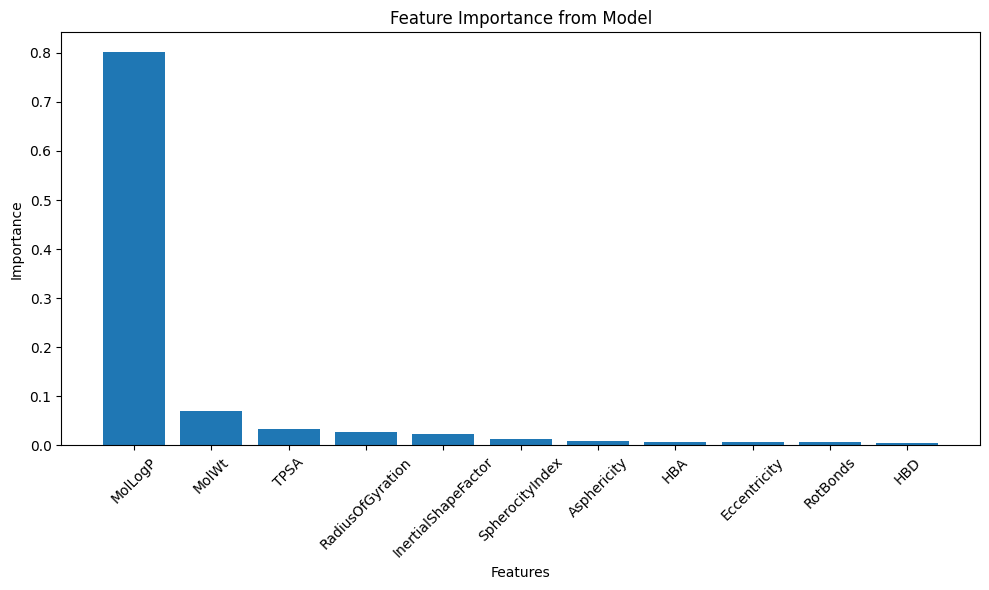

In [11]:
plt.figure(figsize=(10,6))
plt.bar(imp_df["Feature"], imp_df["Importance"])

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance from Model")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [12]:
new_smiles = "c1ccsc1"

mol_new = smiles_to_3d(new_smiles)
new_features = extract_3d_features(mol_new)

X_new = pd.DataFrame([new_features])  # if dict
X_new_scaled = scaler.transform(X_new)

pred = model.predict(X_new_scaled)
print(pred)


[-1.4715]
